# Short-List Promising Models & Fine-Tune the System

**Goal:** find the model that gives the most trustworthy **probability** that a reported squirrel has nutosis, so animal control can send an agent when that probability is **20% or more** (a trip costs **\$200**, a missed diseased squirrel costs $1,000, so sending pays off above 200 / 1,000 = 20%). The final model is saved as `model.pkl`.

**Ground rules from the checklist and the project**
- **The test set stays closed until section 11.** Every choice below (models, settings, calibration, cutoff) is made with cross-validation on the training set only. After the test set has been measured nothing is changed ("don't tweak your model after measuring the generalization error").
- **The preparation is part of every model.** Each model is a pipeline `prep -> model`, so the medians, means and categories are learned again inside each cross-validation fold. This is what the Preparation notebook promised, and it avoids leaking validation rows into the preparation.
- **Cross-validation holds out whole squirrels.** Folds are stratified (each has about 12.5% diseased) and grouped by `Unique Squirrel ID`, so the same squirrel is never on both sides.
- **No data is saved.** Only `model.pkl` (and `preprocessor.pkl`, so the two files match) are created.

| Checklist step | Section |
|---|---|
| Short-list 1-2: train many quick models, compare with cross-validation (mean and standard deviation) | 3 |
| Short-list 3: most significant variables | 4 |
| Short-list 4: types of errors | 5 |
| Short-list 5-6: feature selection and engineering round | 6 |
| Short-list 7: pick the top 3 to 5 models, preferring different errors | 7 |
| Fine-tune 1: hyperparameters by cross-validation, preparation choices as hyperparameters, random search | 8 |
| Fine-tune 2: calibration and ensemble | 9 |
| Cutoff and capacity check (from the business objective) | 10 |
| Fine-tune 3: measure on the test set, once | 11 |
| Save `model.pkl`, summary and limitations | 12 |

Section 1 and 2 set up the data, the cost measure and the cross-validation.


In [1]:
# Imports
from custom_transformers import *
import warnings
from itertools import product
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier, VotingClassifier)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import SVC

In [2]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)

SEED = 42
TARGET = "diseased"
TRIP_COST, MISS_COST = 200, 1000                # dollars: one trip / one diseased squirrel left alone
THRESHOLD = TRIP_COST / MISS_COST               # send an agent when the probability is at least this (0.20)

## 1. Set-up: data, cost measure and the numbers to beat

**What goes into the models.** Only columns that exist when a report arrives: the census columns the Preparation notebook kept, the distances to named places, and (only for two tests in section 6) the three notes columns and the day-level weather and calendar columns. The ID and the label are not inputs. `Unique Squirrel ID` and `date` are kept **apart**, only to build the folds.

**How a model is judged.** Four measures, because the output is a probability that will be compared with 20%:

| Measure | Meaning | Better is |
|---|---|---|
| **Log loss** | How good the probabilities are (punishes confident mistakes). Main measure for choosing models | lower |
| **Brier score** | Average squared gap between the probability and what happened | lower |
| **Cost per 1,000 sightings** | Dollars lost if an agent is sent whenever the probability is 20% or more (trips plus missed squirrels). The business measure | lower |
| **Recall and % sent** | Share of diseased squirrels reached, and share of reports that get an agent | recall higher |
| AUC | How well the models rank squirrels, whatever the cutoff | higher |

The cost is noisy (about 300 diseased squirrels in training), so **log loss chooses, and cost confirms**.

In [3]:
train = pd.read_parquet("train_set.parquet")          # the test set is NOT opened here
y_train = train[TARGET].astype(int)
ids = train["Unique Squirrel ID"]                      # used only to keep a squirrel's rows together in the folds
days = train["date"]                                   # used only for day-grouped folds and the capacity check

geo_inputs = sorted(c for c in train.columns if c.startswith("geo_dist_")) + ["geo_nearest_place_kind"]
MODEL_INPUTS = REQUIRED_COLUMNS + geo_inputs           # what the default recipe uses
DAY_INPUTS = DAY_LEVEL_NUMERIC + DAY_LEVEL_BINARY      # only used by the keep_day_level test
TEXT_INPUTS = TEXT_COLUMNS                             # the notes columns, only used by the keyword similarity test
X_train = train[MODEL_INPUTS + TEXT_INPUTS + DAY_INPUTS]

print(f"{len(train):,} training sightings | {y_train.sum()} diseased ({y_train.mean():.1%}) | "
      f"{ids.nunique():,} squirrels | {days.nunique()} days")
print(f"{len(MODEL_INPUTS)} input columns (+ {len(TEXT_INPUTS)} notes columns and {len(DAY_INPUTS)} day-level columns, each for one test)")

2,418 training sightings | 303 diseased (12.5%) | 2,415 squirrels | 11 days
25 input columns (+ 3 notes columns and 8 day-level columns, each for one test)


In [4]:
def decision_summary(y, send):
    """Cost and reach of a yes/no decision to send an agent."""
    y, send = np.asarray(y).astype(bool), np.asarray(send).astype(bool)
    cost = TRIP_COST * send.sum() + MISS_COST * (y & ~send).sum()
    return {"cost": cost, "cost_per_1000": 1000 * cost / len(y), "recall": (y & send).sum() / y.sum(),
            "pct_sent": send.mean()}


def score(y, p):
    """All measures for one set of probabilities p."""
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    decision = decision_summary(y, p >= THRESHOLD)
    return {"log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p), "auc": roc_auc_score(y, p),
            "cost_per_1000": decision["cost_per_1000"], "recall": decision["recall"], "pct_sent": decision["pct_sent"]}


# The numbers to beat: no model at all
fur = train["Primary Fur Color"]
baselines = {"Never send anyone": np.zeros(len(y_train), bool),
             "Always send": np.ones(len(y_train), bool),
             "Send if black or cinnamon": fur.isin(["Black", "Cinnamon"]).to_numpy()}
table = pd.DataFrame({name: decision_summary(y_train, send) for name, send in baselines.items()}).T
table["cost"] = table["cost"].map("${:,.0f}".format)
table["cost_per_1000"] = table["cost_per_1000"].map("${:,.0f}".format)
table["recall"] = table["recall"].map("{:.0%}".format)
table["pct_sent"] = table["pct_sent"].map("{:.0%}".format)
table

,cost,cost_per_1000,recall,pct_sent
Never send anyone,"$303,000","$125,310",0%,0%
Always send,"$483,600","$200,000",100%,100%
Send if black or cinnamon,"$175,800","$72,705",68%,16%


## 2. Cross-validation

Every comparison below uses the **same 5 folds**, so differences between two models are not just a different luck of the draw. Each fold keeps about 12.5% diseased, and a squirrel's rows (5 IDs appear twice) never end up in two folds.

`cv_evaluate` trains a fresh copy of the whole pipeline on 4 folds, predicts the 5th, and repeats. It returns the scores of each fold (to get the **mean and standard deviation**, as the checklist asks) and the out-of-fold probabilities (what each squirrel would have been given if it had not been used for training).

In [5]:
def make_cv(seed=SEED, n_splits=5):
    return StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)


def cv_evaluate(model, cv=None, groups=None, X=None, y=None):
    """Scores per fold (a table) and out-of-fold probabilities (an array)."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    cv = make_cv() if cv is None else cv
    groups = ids if groups is None else groups
    oof, rows = np.full(len(y), np.nan), []
    for tr, va in cv.split(X, y, groups):
        fitted = clone(model).fit(X.iloc[tr], y.iloc[tr])
        p = fitted.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p
        rows.append(score(y.iloc[va], p))
    return pd.DataFrame(rows), oof


FORMATS = {"log_loss": "{:.3f}", "brier": "{:.4f}", "auc": "{:.3f}", "cost_per_1000": "${:,.0f}",
           "recall": "{:.0%}", "pct_sent": "{:.0%}"}


def compare(results, sort_by="log_loss"):
    """Table of mean +- standard deviation over the folds, best first. Also returns the plain means."""
    means = pd.DataFrame({n: f.mean() for n, f in results.items()}).T.sort_values(sort_by)
    stds = pd.DataFrame({n: f.std() for n, f in results.items()}).T.loc[means.index]
    shown = pd.DataFrame({c: [FORMATS[c].format(means.loc[n, c]) + " ± " + FORMATS[c].format(stds.loc[n, c])
                              for n in means.index] for c in FORMATS}, index=means.index)
    return shown, means


def verdict(base, new, metric="log_loss"):
    """Is `new` really better than `base` on the same folds? (lower is better)  Needs a win in at least 4 of 5 folds."""
    d = new[metric].to_numpy() - base[metric].to_numpy()
    wins = int((d < 0).sum())
    label = "better" if (wins >= len(d) - 1 and d.mean() < 0) else \
            "worse" if (wins <= 1 and d.mean() > 0) else "no clear difference"
    return label, d.mean(), wins


# Check the folds
checks = []
for k, (tr, va) in enumerate(make_cv().split(X_train, y_train, ids), 1):
    assert not set(ids.iloc[tr]) & set(ids.iloc[va]), "a squirrel is on both sides of a fold"
    checks.append({"fold": k, "train rows": len(tr), "validation rows": len(va),
                   "diseased in validation": int(y_train.iloc[va].sum()),
                   "share diseased": round(y_train.iloc[va].mean(), 3)})
pd.DataFrame(checks).set_index("fold")

,train rows,validation rows,diseased in validation,share diseased
fold,,,,
1,1934,484,61,0.126
2,1935,483,60,0.124
3,1935,483,60,0.124
4,1934,484,61,0.126
5,1934,484,61,0.126


## 3. Short-list, steps 1 and 2: many quick models, compared by cross-validation

One model from each family, with **standard settings** (only a few changes so the probabilities are usable, noted below). The preparation is the default recipe from the Preparation notebook.

- **No class weights.** Making the diseased class "count more" would push probabilities up and ruin the 20% comparison. The cost trade-off is handled by the cutoff instead.
- `Prior (no features)` always answers with the training rate (12.5%). It is the floor for log loss and Brier score.
- The random forest and extra trees use `min_samples_leaf=5`, otherwise single leaves give probabilities of exactly 0 or 1. The neural net has a strong L2 penalty (`alpha=1`), which keeps it from memorizing and lets it converge. A plain SVM gives no probabilities, so it is wrapped in a sigmoid correction learned with its own internal 5-fold split (the way scikit-learn now recommends).

In [6]:
def with_prep(estimator, **prep_settings):
    """The full pipeline: preparation first, then the model. The preparation is refitted inside every fold."""
    return Pipeline([("prep", make_preprocessor(**prep_settings)), ("model", estimator)])


CANDIDATES = {
    "Prior (no features)":  DummyClassifier(strategy="prior"),
    "Logistic regression":  LogisticRegression(max_iter=2000),
    "Naive Bayes":          GaussianNB(),
    "k nearest neighbours": KNeighborsClassifier(n_neighbors=25),
    "SVM (RBF)":            CalibratedClassifierCV(SVC(random_state=SEED), method="sigmoid", cv=5, ensemble=False),
    "Random forest":        RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Extra trees":          ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Gradient boosting":    HistGradientBoostingClassifier(random_state=SEED),
    "Neural net (MLP)":     MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=2000, tol=1e-3, random_state=SEED),
}

results, OOF = {}, {}
for name, estimator in CANDIDATES.items():
    results[name], OOF[name] = cv_evaluate(with_prep(estimator))
    print(f"done: {name}")

shown, means = compare(results)
print("\nMean ± standard deviation over the 5 folds, best log loss first")
shown

done: Prior (no features)
done: Logistic regression
done: Naive Bayes
done: k nearest neighbours
done: SVM (RBF)
done: Random forest
done: Extra trees
done: Gradient boosting
done: Neural net (MLP)

Mean ± standard deviation over the 5 folds, best log loss first


,log_loss,brier,auc,cost_per_1000,recall,pct_sent
Extra trees,0.262 ± 0.010,0.0746 ± 0.0025,0.848 ± 0.023,"$73,864 ± $2,879",69% ± 3%,18% ± 1%
Random forest,0.264 ± 0.010,0.0752 ± 0.0019,0.842 ± 0.025,"$73,201 ± $2,192",70% ± 3%,18% ± 1%
Logistic regression,0.266 ± 0.007,0.0746 ± 0.0033,0.828 ± 0.013,"$72,788 ± $2,975",68% ± 4%,17% ± 1%
Neural net (MLP),0.268 ± 0.006,0.0758 ± 0.0021,0.823 ± 0.013,"$73,284 ± $2,245",68% ± 4%,17% ± 1%
SVM (RBF),0.280 ± 0.007,0.0798 ± 0.0025,0.821 ± 0.021,"$79,074 ± $2,023",56% ± 3%,12% ± 1%
Gradient boosting,0.315 ± 0.018,0.0820 ± 0.0036,0.834 ± 0.024,"$80,067 ± $3,905",59% ± 5%,14% ± 2%
Prior (no features),0.377 ± 0.002,0.1096 ± 0.0007,0.500 ± 0.000,"$125,309 ± $991",0% ± 0%,0% ± 0%
k nearest neighbours,0.400 ± 0.066,0.0901 ± 0.0033,0.783 ± 0.039,"$87,760 ± $4,008",51% ± 4%,13% ± 1%
Naive Bayes,1.474 ± 0.445,0.1827 ± 0.0944,0.802 ± 0.014,"$95,605 ± $36,322",74% ± 9%,31% ± 23%


**How to read the table.**
- A model is only clearly better than another when the gap is **larger than the ± next to it**. With about 60 diseased squirrels per fold the standard deviations are wide, so small gaps are noise.
- **Log loss and Brier score** tell how good the probabilities are. **Cost** tells what the 20% rule does with them. A model can rank squirrels well (high AUC) and still have badly scaled probabilities, which is why section 9 calibrates them.
- Compare the cost with the baselines in section 1 (never send, always send, "black or cinnamon"). Any model that does not beat "black or cinnamon" on cost is not worth using.

## 4. Short-list, step 3: most significant variables

**Permutation importance** shuffles one raw input column at a time in the validation fold and measures how much the log loss gets **worse**. A big increase means the model relied on that column. It is computed on held-out folds for the three best models, then averaged over the folds.

For the logistic regression, the coefficients are also shown (on the standardized scale, so they can be compared).

In [7]:
def cv_permutation_importance(model, n_repeats=5):
    rows = []
    for tr, va in make_cv().split(X_train, y_train, ids):
        fitted = clone(model).fit(X_train.iloc[tr], y_train.iloc[tr])
        r = permutation_importance(fitted, X_train.iloc[va][MODEL_INPUTS], y_train.iloc[va],
                                   scoring="neg_log_loss", n_repeats=n_repeats, random_state=SEED)
        rows.append(pd.Series(r.importances_mean, index=MODEL_INPUTS))
    return pd.concat(rows, axis=1).mean(axis=1)


top3 = [n for n in means.index if n != "Prior (no features)"][:3]
importance = pd.DataFrame({n: cv_permutation_importance(with_prep(CANDIDATES[n])) for n in top3})
importance["average"] = importance.mean(axis=1)
importance = importance.sort_values("average", ascending=False)
print("Increase in log loss when the column is shuffled (higher = more important)")
print(importance.head(12).round(4).to_string())
print(f"\nColumns whose shuffling changes nothing (average below 0.0005): "
      f"{', '.join(importance.index[importance['average'] < 0.0005])}")

Increase in log loss when the column is shuffled (higher = more important)
                                  Extra trees  Random forest  Logistic regression  average
Primary Fur Color                      0.1857         0.1726               0.2383   0.1989
Running                                0.0058         0.0037               0.0045   0.0046
Highlight Fur Color                    0.0044         0.0041               0.0035   0.0040
Climbing                               0.0027         0.0018               0.0049   0.0032
Approaches                             0.0017         0.0019               0.0049   0.0029
Above Ground Sighter Measurement      -0.0000         0.0004               0.0060   0.0021
Chasing                                0.0021         0.0012               0.0011   0.0015
geo_nearest_place_kind                 0.0011         0.0014               0.0015   0.0013
Age                                    0.0021         0.0012               0.0005   0.0013
geo_dist_water_

## 5. Short-list, step 4: the types of errors the models make

Looked at on the **out-of-fold** probabilities of the best model, with the 20% rule. The questions are: which diseased squirrels are missed (each costs $1,000), which trips are wasted (each costs $200), and are the probabilities honest (do squirrels given "30%" turn out diseased about 30% of the time)?

In [8]:
best_name = [n for n in means.index if n != "Prior (no features)"][0]
p_best = OOF[best_name]
send = p_best >= THRESHOLD
y = y_train.to_numpy().astype(bool)
tp, fn, fp, tn = (send & y).sum(), (~send & y).sum(), (send & ~y).sum(), (~send & ~y).sum()

print(f"Best model by log loss: {best_name}  (out-of-fold, send if probability >= {THRESHOLD:.0%})")
print(pd.DataFrame({"squirrels": [tp, fn, fp, tn],
                    "cost": [f"${TRIP_COST * tp:,}", f"${MISS_COST * fn:,}", f"${TRIP_COST * fp:,}", "$0"]},
                   index=["diseased, agent sent (caught)", "diseased, NOT sent (missed)",
                          "healthy, agent sent (wasted trip)", "healthy, not sent"]).to_string())

errors = pd.DataFrame({"fur": fur.fillna("Unknown").to_numpy(), "diseased": y, "sent": send})
errors["missed"] = errors["diseased"] & ~errors["sent"]
errors["wasted trips"] = ~errors["diseased"] & errors["sent"]
by_fur = errors.groupby("fur").agg(squirrels=("diseased", "size"), diseased=("diseased", "sum"),
                                   missed=("missed", "sum"), **{"wasted trips": ("wasted trips", "sum")})
print("\nWhere the errors are, by primary fur color")
print(by_fur.to_string())

missed = p_best[~send & y]
print(f"\nMissed diseased squirrels: median probability given {np.median(missed):.1%}; "
      f"{(missed >= 0.10).mean():.0%} of them were given 10% or more")

Best model by log loss: Extra trees  (out-of-fold, send if probability >= 20%)
                                   squirrels     cost
diseased, agent sent (caught)            210  $42,000
diseased, NOT sent (missed)               93  $93,000
healthy, agent sent (wasted trip)        218  $43,600
healthy, not sent                       1897       $0

Where the errors are, by primary fur color
          squirrels  diseased  missed  wasted trips
fur                                                
Black            83        55       0            28
Cinnamon        311       151       0           159
Gray           1982        89      89             7
Unknown          42         8       4            24

Missed diseased squirrels: median probability given 5.8%; 16% of them were given 10% or more


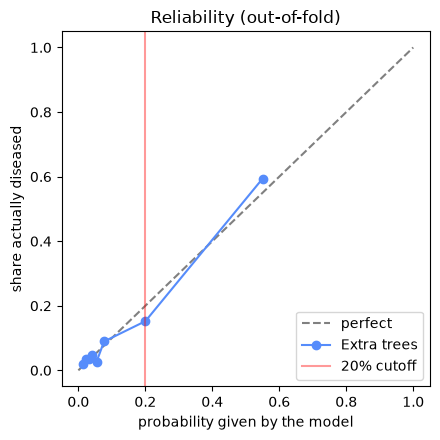

                       0      1      2      3      4      5      6      7
given              0.015  0.024  0.032  0.042  0.054  0.077  0.200  0.550
actually diseased  0.020  0.036  0.036  0.046  0.026  0.089  0.152  0.594


In [9]:
# Are the probabilities honest? Reliability by group of 8 (each group has about the same number of squirrels)
frac_diseased, mean_predicted = calibration_curve(y_train, p_best, n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax.plot(mean_predicted, frac_diseased, "o-", label=best_name)
ax.axvline(THRESHOLD, color="red", alpha=0.4, label="20% cutoff")
ax.set_xlabel("probability given by the model"); ax.set_ylabel("share actually diseased")
ax.set_title("Reliability (out-of-fold)"); ax.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({"given": mean_predicted.round(3), "actually diseased": frac_diseased.round(3)}).T.to_string())

**What a human would have used to avoid the misses.** The census records what a volunteer saw from a distance: fur color, age, behavior and place. It does **not** record the visible signs of the disease itself (patchy fur, skin, thin tail), and the free-text columns do not contain those words either (Exploration, section 8). Missed diseased squirrels that look like healthy gray squirrels in every column are therefore **not fixable with this data**. The list of limitations in section 12 says so. What could fix it later is a field in the app for what the reporter sees (for example "visible hair loss: yes/no").

## 6. Short-list, steps 5 and 6: a quick round of feature selection and engineering

Two quick tests with a fast linear model and a fast tree model, using the same folds so each change is compared **fold by fold**. The verdict rule is strict on purpose: a change counts as `better` (or `worse`) only if it is in the same direction in at least 4 of the 5 folds **and** the average moves the same way. Everything else is `no clear difference`.

**6a. Does a group of columns help?** Each group is removed after the preparation, and the models are refitted.
- `worse` when removed: the group helps, keep it.
- `no clear difference`: the group adds nothing measurable. It can be dropped for simplicity (a setting in `custom_transformers.py` would be added, with approval).
- `better` when removed: drop it.

In [10]:
def drop_columns(df, names):
    """Remove columns by exact name, or by prefix when the name ends with '_'."""
    gone = [c for c in df.columns if any(c == n or (n.endswith("_") and c.startswith(n)) for n in names)]
    return df.drop(columns=gone)


def with_dropped(estimator, names):
    return Pipeline([("prep", make_preprocessor()), ("drop", FunctionTransformer(drop_columns, kw_args={"names": names})),
                     ("model", estimator)])


GROUPS = {"Shift": ["Shift_"], "Age": ["Age_"], "Location (ground plane, above ground)": ["Location_"],
          "Highlight fur colors": ["highlight_"], "Height above ground": ["height_ft", "height_missing"],
          "Named places (distances and kind)": ["geo_"],
          "All behaviors except Approaches": [b for b in BEHAVIORS if b != "Approaches"],
          "All 13 behaviors": BEHAVIORS, "Coordinates X and Y": ["X", "Y"]}
FAST = {"Logistic regression": CANDIDATES["Logistic regression"], "Gradient boosting": CANDIDATES["Gradient boosting"]}

prepared_columns = make_preprocessor().fit_transform(X_train).columns
rows = []
for group, names in GROUPS.items():
    removed = len(prepared_columns) - len(drop_columns(pd.DataFrame(columns=prepared_columns), names).columns)
    row = {"group removed": group, "columns removed": removed}
    for model_name, estimator in FAST.items():
        v, delta, wins = verdict(results[model_name], cv_evaluate(with_dropped(estimator, names))[0])
        row[model_name] = f"{v} ({delta:+.4f}, {wins}/5 folds)"
    rows.append(row)
print("Change in log loss when the group is removed (negative = better without it). Win = removal better in that fold.")
pd.DataFrame(rows).set_index("group removed")

Change in log loss when the group is removed (negative = better without it). Win = removal better in that fold.


,columns removed,Logistic regression,Gradient boosting
group removed,,,
Shift,2,"worse (+0.0001, 1/5 folds)","no clear difference (-0.0008, 3/5 folds)"
Age,3,"no clear difference (-0.0003, 3/5 folds)","no clear difference (-0.0027, 3/5 folds)"
"Location (ground plane, above ground)",3,"better (-0.0010, 4/5 folds)","no clear difference (-0.0027, 3/5 folds)"
Highlight fur colors,4,"no clear difference (+0.0006, 2/5 folds)","worse (+0.0008, 1/5 folds)"
Height above ground,2,"no clear difference (-0.0007, 2/5 folds)","better (-0.0091, 5/5 folds)"
Named places (distances and kind),6,"better (-0.0010, 4/5 folds)","better (-0.0093, 4/5 folds)"
All behaviors except Approaches,12,"worse (+0.0026, 0/5 folds)","worse (+0.0152, 0/5 folds)"
All 13 behaviors,13,"worse (+0.0061, 0/5 folds)","worse (+0.0103, 1/5 folds)"
Coordinates X and Y,2,"no clear difference (-0.0001, 3/5 folds)","no clear difference (-0.0002, 3/5 folds)"


**6b. Do the weather and calendar columns help?** There are only 11 distinct days, so a day-level column can act as a hidden "which day was it" code. With ordinary folds a model could use it to recognize days it has already seen, which would look good and be useless for a new day. The fair test holds out **whole days**: the folds below are grouped by `date`. Both versions (with and without the day-level columns) are scored on those same day-grouped folds.

In [11]:
day_cv = GroupKFold(n_splits=5)
day_rows, day_verdicts = [], {}
for model_name, estimator in FAST.items():
    base, _ = cv_evaluate(with_prep(estimator), cv=day_cv, groups=days)
    with_days, _ = cv_evaluate(with_prep(estimator, keep_day_level=True), cv=day_cv, groups=days)
    v, delta, wins = verdict(base, with_days)
    day_verdicts[model_name] = v
    day_rows.append({"model": model_name, "log loss without": base["log_loss"].mean().round(4),
                     "log loss with": with_days["log_loss"].mean().round(4), "verdict": f"{v} ({delta:+.4f}, {wins}/5 folds)"})
print("Folds hold out whole days. Negative change = the day-level columns help.")
pd.DataFrame(day_rows).set_index("model")

Folds hold out whole days. Negative change = the day-level columns help.


,log loss without,log loss with,verdict
model,,,
Logistic regression,0.2760,0.3309,"worse (+0.0549, 0/5 folds)"
Gradient boosting,0.3593,0.3143,"better (-0.0450, 5/5 folds)"


**6c. Do the notes help?** The Preparation notebook can add columns built from the three notes columns: the **cosine similarity** between a note and four themes of symptom keywords (`kw_aggression`, `kw_foaming`, `kw_fur`, `kw_ill`, and `kw_any`, the largest of them), and a flag `has_note`. The keywords were chosen from the symptoms in the Frame step, not from the labels. Two versions are compared with the default recipe, on the same folds as before:
- **keywords + has_note:** the full setting `use_keyword_similarity=True`.
- **keywords only:** the same, with `has_note` removed. If this version shows no gain but the full one does, the gain comes from **whether a note exists**, not from what it says.

The setting is added to the final recipe only if the full version is `better` for at least one of the two models and `worse` for none. Look at the **size** of the change as well as the verdict: a gain of 0.0001 in log loss is not a real improvement, even if it wins in all 5 folds.

In [12]:
text_check = make_preprocessor(use_keyword_similarity=True).fit_transform(X_train)
print(f"Notes: {int(text_check['has_note'].sum()):,} of {len(X_train):,} training sightings have a note | "
      f"{int((text_check['kw_any'] > 0).sum())} match any keyword at all\n")

text_rows, text_verdicts = [], {}
for model_name, estimator in FAST.items():
    full = cv_evaluate(with_prep(estimator, use_keyword_similarity=True))[0]
    keywords_only = cv_evaluate(Pipeline([("prep", make_preprocessor(use_keyword_similarity=True)),
                                          ("drop", FunctionTransformer(drop_columns, kw_args={"names": ["has_note"]})),
                                          ("model", estimator)]))[0]
    v_full, d_full, w_full = verdict(results[model_name], full)
    v_kw, d_kw, w_kw = verdict(results[model_name], keywords_only)
    text_verdicts[model_name] = v_full
    text_rows.append({"model": model_name, "keywords + has_note": f"{v_full} ({d_full:+.4f}, {w_full}/5 folds)",
                      "keywords only": f"{v_kw} ({d_kw:+.4f}, {w_kw}/5 folds)"})
print("Change in log loss against the default recipe (negative = the notes help).")
pd.DataFrame(text_rows).set_index("model")

Notes: 572 of 2,418 training sightings have a note | 11 match any keyword at all

Change in log loss against the default recipe (negative = the notes help).


,keywords + has_note,keywords only
model,,
Logistic regression,"better (-0.0070, 5/5 folds)","no clear difference (-0.0001, 3/5 folds)"
Gradient boosting,"better (-0.0157, 5/5 folds)","no clear difference (+0.0000, 0/5 folds)"


**How to use 6a, 6b and 6c.** Nothing here changes the recipe by itself. The tuning in section 8 treats the **preparation settings** as hyperparameters. The day-level columns are only added to the final recipe if **both** models in 6b say `better`, and the notes columns only if 6c says `better` for at least one model and `worse` for none. The engineered columns from the Preparation notebook (`height_ft`, the highlight colors) are tested again in the section 8 grid.

## 7. Short-list, step 7: the top models, preferring different errors

The best models by log loss are kept, but a model is skipped if its probabilities are almost the same as one already chosen (correlation above 0.98 on the out-of-fold probabilities). A short-list made of near-copies cannot improve an ensemble. At most 4 models go on to tuning, and always at least 3.

In [13]:
ranked = [n for n in means.index if n != "Prior (no features)"]
corr = pd.DataFrame({n: OOF[n] for n in ranked}).corr()

SHORTLIST = []
for n in ranked:
    if len(SHORTLIST) < 4 and all(corr.loc[n, c] <= 0.98 for c in SHORTLIST):
        SHORTLIST.append(n)
for n in ranked:                                  # make sure there are at least 3
    if len(SHORTLIST) < 3 and n not in SHORTLIST:
        SHORTLIST.append(n)

print("Correlation of the out-of-fold probabilities (1.00 = the models give the same answers)")
print(corr.loc[ranked, ranked].round(2).to_string())
print("\nShort-list:", SHORTLIST)

Correlation of the out-of-fold probabilities (1.00 = the models give the same answers)
                      Extra trees  Random forest  Logistic regression  Neural net (MLP)  SVM (RBF)  Gradient boosting  k nearest neighbours  Naive Bayes
Extra trees                  1.00           0.98                 0.95              0.96       0.90               0.86                  0.82         0.75
Random forest                0.98           1.00                 0.94              0.96       0.89               0.88                  0.83         0.75
Logistic regression          0.95           0.94                 1.00              0.98       0.87               0.83                  0.75         0.74
Neural net (MLP)             0.96           0.96                 0.98              1.00       0.90               0.84                  0.82         0.75
SVM (RBF)                    0.90           0.89                 0.87              0.90       1.00               0.82                  0.78         

## 8. Fine-tune, step 1: preparation settings and hyperparameters

**8a. Preparation settings as hyperparameters.** The checklist says to treat data transformation choices as hyperparameters, especially when unsure. There are few values, so a **grid** is used (all 32 combinations) with the two fast models. The default recipe is kept **unless** another combination is better in at least 4 of the 5 folds when the two models are averaged.

In [14]:
GRID = {"log_height": [True, False], "use_highlight_colors": [True, False], "use_nearest_place_kind": [True, False],
        "scaler": ["standard", "robust"], "min_category_count": [5, 20]}
DEFAULT_SETTINGS = {"log_height": True, "use_highlight_colors": True, "use_nearest_place_kind": True,
                    "scaler": "standard", "min_category_count": 5}

grid_rows, grid_folds = [], {}
for values in product(*GRID.values()):
    settings = dict(zip(GRID, values))
    per_model = [cv_evaluate(with_prep(est, **settings))[0]["log_loss"].to_numpy() for est in FAST.values()]
    grid_folds[values] = np.mean(per_model, axis=0)            # average of the two models, per fold
    grid_rows.append({**settings, "log_loss": grid_folds[values].mean()})
grid = pd.DataFrame(grid_rows).sort_values("log_loss").reset_index(drop=True)

default_key = tuple(DEFAULT_SETTINGS.values())
best_key = tuple(v.item() if hasattr(v, "item") else v for v in grid.iloc[0][list(GRID)])      # plain Python values
delta = grid_folds[best_key] - grid_folds[default_key]
wins = int((delta < 0).sum())
PREP_SETTINGS = dict(zip(GRID, best_key)) if (wins >= 4 and delta.mean() < 0) else dict(DEFAULT_SETTINGS)

print("Five best combinations (average log loss of the two fast models):")
print(grid.head(5).round(4).to_string())
print(f"\nDefault recipe: log loss {grid_folds[default_key].mean():.4f}. Best combination beats it in {wins}/5 folds "
      f"(average change {delta.mean():+.4f}).")

# Day-level columns: only if the day-grouped test in section 6b said 'better' for BOTH models
if all(v == "better" for v in day_verdicts.values()):
    PREP_SETTINGS["keep_day_level"] = True
# Notes (keyword similarity): only if section 6c said 'better' for at least one model and 'worse' for none
if any(v == "better" for v in text_verdicts.values()) and not any(v == "worse" for v in text_verdicts.values()):
    PREP_SETTINGS["use_keyword_similarity"] = True
print("\nChosen preparation settings:", PREP_SETTINGS)

Five best combinations (average log loss of the two fast models):
   log_height  use_highlight_colors  use_nearest_place_kind    scaler  min_category_count  log_loss
0       False                  True                   False    robust                  20    0.2881
1       False                  True                   False    robust                   5    0.2881
2       False                  True                   False  standard                  20    0.2882
3       False                  True                   False  standard                   5    0.2882
4        True                  True                   False    robust                   5    0.2882

Default recipe: log loss 0.2902. Best combination beats it in 4/5 folds (average change -0.0021).

Chosen preparation settings: {'log_height': False, 'use_highlight_colors': True, 'use_nearest_place_kind': False, 'scaler': 'robust', 'min_category_count': 20, 'use_keyword_similarity': True}


**8b. Hyperparameters, by random search.** For each short-listed model, 20 random settings are tried with the chosen preparation, scored by **log loss** on the same 5 grouped folds (random search because there are many settings per model). Log loss is used here, not cost, because cost at one cutoff is a step function with only about 300 diseased squirrels: it is too noisy to steer a search. The cutoff is dealt with in section 10.

The score a search reports is slightly **optimistic**, because the best of 20 tries is picked on those same folds. That is why section 9 checks the tuned models again on **fresh folds** that were not used for the search.

In [15]:
N_ITER = 20
SPACES = {
    "Logistic regression":  {"C": loguniform(1e-3, 1e2)},
    "Naive Bayes":          {"var_smoothing": loguniform(1e-9, 1e-2)},
    "k nearest neighbours": {"n_neighbors": randint(10, 100), "weights": ["uniform", "distance"]},
    "SVM (RBF)":            {"estimator__C": loguniform(1e-2, 1e2), "estimator__gamma": loguniform(1e-3, 1e-1)},
    "Random forest":        {"n_estimators": randint(200, 500), "min_samples_leaf": randint(2, 30),
                             "max_features": uniform(0.1, 0.6), "max_depth": [None, 4, 6, 8]},
    "Extra trees":          {"n_estimators": randint(200, 500), "min_samples_leaf": randint(2, 30),
                             "max_features": uniform(0.1, 0.6), "max_depth": [None, 4, 6, 8]},
    "Gradient boosting":    {"learning_rate": loguniform(0.01, 0.2), "max_iter": randint(50, 400),
                             "max_leaf_nodes": randint(3, 16), "min_samples_leaf": randint(10, 80),
                             "l2_regularization": loguniform(1e-3, 10)},
    "Neural net (MLP)":     {"hidden_layer_sizes": [(16,), (32,), (64,), (32, 16)], "alpha": loguniform(0.1, 10),
                             "learning_rate_init": loguniform(1e-3, 1e-2)},
}

TUNED, tuning_rows = {}, []
for name in SHORTLIST:
    search = RandomizedSearchCV(with_prep(CANDIDATES[name], **PREP_SETTINGS),
                                {f"model__{k}": v for k, v in SPACES[name].items()},
                                n_iter=N_ITER, scoring="neg_log_loss", cv=make_cv(), n_jobs=-1,
                                random_state=SEED, refit=True)
    search.fit(X_train, y_train, groups=ids)
    TUNED[name] = clone(search.best_estimator_.named_steps["model"])          # the model with its best settings, unfitted
    tuning_rows.append({"model": name, "log loss before": means.loc[name, "log_loss"],
                        "log loss after (search)": -search.best_score_,
                        "best settings": {k.split("__", 1)[1]: (round(v, 4) if isinstance(v, float) else v)
                                          for k, v in search.best_params_.items()}})
    print(f"done: {name}")
pd.DataFrame(tuning_rows).set_index("model")

done: Extra trees
done: Logistic regression
done: SVM (RBF)
done: Gradient boosting


,log loss before,log loss after (search),best settings
model,,,
Extra trees,0.262246,0.254460,"{'max_depth': 6, 'max_features': 0.5779, 'min_samples_leaf': 16, 'n_estimato..."
Logistic regression,0.265761,0.258363,{'C': 0.4205}
SVM (RBF),0.280413,0.274779,"{'estimator__C': 8.4718, 'estimator__gamma': 0.0158}"
Gradient boosting,0.314603,0.253236,"{'l2_regularization': 0.4014, 'learning_rate': 0.0118, 'max_iter': 393, 'max..."


## 9. Fine-tune, step 2: calibration and an ensemble

**Calibration.** The cutoff of 20% only means "send when it pays off" if a probability of 20% really means 1 in 5. Some models (forests, SVMs, nearest neighbours, naive Bayes) are not honest about this. For each tuned model, three versions are compared on **fresh folds** (a different split than the one used for tuning): as it is, with a **sigmoid** correction, and with an **isotonic** correction (both learned inside the training part with an internal 5-fold split, so they never see the validation fold).

**Ensemble.** The tuned and calibrated models are then averaged (their probabilities), as the checklist suggests. The ensemble and each single model are compared on the same fresh folds, and the one with the **lowest log loss** is the final model.

In [16]:
FRESH = make_cv(seed=7)                                   # a different split from the one used for tuning


def calibrated(estimator, method):
    return clone(estimator) if method is None else CalibratedClassifierCV(clone(estimator), method=method, cv=5)


calibration_results, best_method = {}, {}
for name in SHORTLIST:
    scores = {m: cv_evaluate(with_prep(calibrated(TUNED[name], m), **PREP_SETTINGS), cv=FRESH)[0]
              for m in (None, "sigmoid", "isotonic")}
    for m, s in scores.items():
        calibration_results[f"{name} | {m or 'as it is'}"] = s
    best_method[name] = min(scores, key=lambda m: scores[m]["log_loss"].mean())

shown_cal, _ = compare(calibration_results)
print("Fresh folds. Best calibration per model:", {n: (m or "as it is") for n, m in best_method.items()})
shown_cal

Fresh folds. Best calibration per model: {'Extra trees': 'as it is', 'Logistic regression': 'as it is', 'SVM (RBF)': 'isotonic', 'Gradient boosting': 'sigmoid'}


,log_loss,brier,auc,cost_per_1000,recall,pct_sent
Extra trees | as it is,0.258 ± 0.030,0.0745 ± 0.0085,0.863 ± 0.039,"$71,714 ± $8,915",73% ± 7%,19% ± 3%
Extra trees | sigmoid,0.260 ± 0.026,0.0747 ± 0.0085,0.862 ± 0.042,"$73,037 ± $9,248",68% ± 8%,16% ± 2%
Logistic regression | as it is,0.261 ± 0.032,0.0744 ± 0.0096,0.850 ± 0.050,"$72,043 ± $9,633",70% ± 8%,17% ± 3%
Logistic regression | sigmoid,0.261 ± 0.030,0.0746 ± 0.0091,0.851 ± 0.049,"$72,043 ± $9,641",70% ± 8%,17% ± 3%
Gradient boosting | sigmoid,0.262 ± 0.029,0.0750 ± 0.0078,0.857 ± 0.045,"$75,518 ± $8,661",71% ± 7%,19% ± 3%
Gradient boosting | isotonic,0.263 ± 0.035,0.0746 ± 0.0089,0.856 ± 0.047,"$74,525 ± $8,637",70% ± 6%,18% ± 3%
Gradient boosting | as it is,0.263 ± 0.036,0.0747 ± 0.0095,0.854 ± 0.049,"$74,277 ± $9,702",71% ± 7%,19% ± 2%
Logistic regression | isotonic,0.265 ± 0.042,0.0743 ± 0.0104,0.849 ± 0.055,"$71,712 ± $9,230",69% ± 7%,16% ± 3%
Extra trees | isotonic,0.270 ± 0.041,0.0748 ± 0.0090,0.862 ± 0.044,"$72,623 ± $8,535",72% ± 8%,19% ± 4%
SVM (RBF) | isotonic,0.273 ± 0.030,0.0767 ± 0.0078,0.823 ± 0.046,"$75,352 ± $7,643",64% ± 6%,15% ± 1%


In [17]:
def ensemble_pipeline(members):
    voting = VotingClassifier([(f"m{i}", calibrated(TUNED[n], best_method[n])) for i, n in enumerate(members)],
                              voting="soft")
    return with_prep(voting, **PREP_SETTINGS)


FINAL_CANDIDATES = {f"{n} (tuned, calibrated)": (lambda n=n: with_prep(calibrated(TUNED[n], best_method[n]), **PREP_SETTINGS))
                    for n in SHORTLIST}
FINAL_CANDIDATES["Ensemble (average of the short-list)"] = lambda: ensemble_pipeline(SHORTLIST)

final_results, FINAL_OOF = {}, {}
for name, build in FINAL_CANDIDATES.items():
    final_results[name], FINAL_OOF[name] = cv_evaluate(build(), cv=FRESH)
final_results["Prior (no features)"], _ = cv_evaluate(with_prep(CANDIDATES["Prior (no features)"], **PREP_SETTINGS), cv=FRESH)

shown_final, final_means = compare(final_results)
FINAL_NAME = [n for n in final_means.index if n != "Prior (no features)"][0]
print("Fresh folds, mean ± standard deviation. Final model = lowest log loss:", FINAL_NAME)
shown_final

Fresh folds, mean ± standard deviation. Final model = lowest log loss: Ensemble (average of the short-list)


,log_loss,brier,auc,cost_per_1000,recall,pct_sent
Ensemble (average of the short-list),0.256 ± 0.028,0.0733 ± 0.0082,0.863 ± 0.046,"$73,532 ± $8,086",69% ± 7%,17% ± 3%
"Extra trees (tuned, calibrated)",0.258 ± 0.030,0.0745 ± 0.0085,0.863 ± 0.039,"$71,714 ± $8,915",73% ± 7%,19% ± 3%
"Logistic regression (tuned, calibrated)",0.261 ± 0.032,0.0744 ± 0.0096,0.850 ± 0.050,"$72,043 ± $9,633",70% ± 8%,17% ± 3%
"Gradient boosting (tuned, calibrated)",0.262 ± 0.029,0.0750 ± 0.0078,0.857 ± 0.045,"$75,518 ± $8,661",71% ± 7%,19% ± 3%
"SVM (RBF) (tuned, calibrated)",0.273 ± 0.030,0.0767 ± 0.0078,0.823 ± 0.046,"$75,352 ± $7,643",64% ± 6%,15% ± 1%
Prior (no features),0.377 ± 0.002,0.1096 ± 0.0007,0.500 ± 0.000,"$125,309 ± $991",0% ± 0%,0% ± 0%


## 10. The cutoff, and the capacity check

**Cutoff.** If the probabilities are honest, the cheapest rule is to send when the probability is above 200 / 1,000 = **20%**. The curve below checks that on the out-of-fold probabilities of the final model. The cutoff is **kept at 20%** even if another value looks slightly cheaper, because the curve is flat near its bottom and picking its lowest point would only fit noise (tuning the cutoff on the same squirrels used to find it).

**Capacity.** The Frame step set a capacity of 40 to 50 captures per day. The census covered 3,023 sightings over 11 days (about 275 a day), so 45 captures is roughly **16% of the sightings**. If the 20% rule sends more reports than that, the agents can only go to the **most likely** ones each day. The table shows what the rule costs with and without that limit. (This treats "captures" as trips and the daily volume of the census as the daily volume of real reports. Both are assumptions to confirm.)

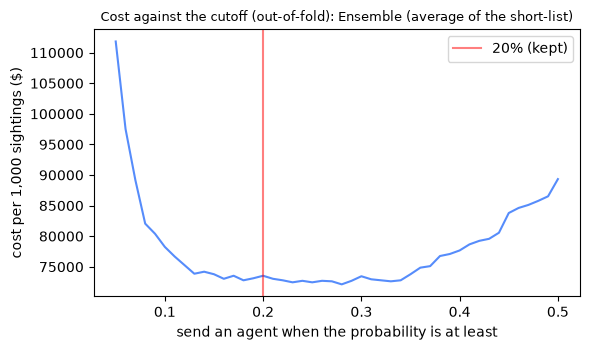

Cost at 20%: $73,532 per 1,000 | cheapest point on the curve: 28% at $72,126


In [18]:
p_final = FINAL_OOF[FINAL_NAME]
thresholds = np.round(np.arange(0.05, 0.505, 0.01), 2)
curve = np.array([decision_summary(y_train, p_final >= t)["cost_per_1000"] for t in thresholds])

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(thresholds, curve); ax.axvline(THRESHOLD, color="red", alpha=0.5, label="20% (kept)")
ax.set_xlabel("send an agent when the probability is at least"); ax.set_ylabel("cost per 1,000 sightings ($)")
ax.set_title(f"Cost against the cutoff (out-of-fold): {FINAL_NAME}", fontsize=9); ax.legend(); plt.tight_layout(); plt.show()
print(f"Cost at 20%: ${curve[thresholds == THRESHOLD][0]:,.0f} per 1,000 | cheapest point on the curve: "
      f"{thresholds[curve.argmin()]:.0%} at ${curve.min():,.0f}")

In [19]:
DAILY_CAPACITY = 45                                       # middle of the 40 to 50 captures per day set in the Frame step
SIGHTINGS_PER_DAY = 3023 / 11                             # census: 3,023 sightings over 11 days (Get the Data step)
CAPACITY_SHARE = DAILY_CAPACITY / SIGHTINGS_PER_DAY       # about 16% of the sightings of a day


def apply_capacity(p, day, threshold=THRESHOLD, share=CAPACITY_SHARE):
    """Send when p >= threshold, but never to more than `share` of a day's sightings (the highest p first)."""
    df = pd.DataFrame({"p": np.asarray(p, dtype=float), "day": np.asarray(day)})
    rank = df.groupby("day")["p"].rank(method="first", ascending=False)
    cap = np.floor(share * df.groupby("day")["p"].transform("size"))
    return ((df["p"] >= threshold) & (rank <= cap)).to_numpy()


rows = {"20% rule, no capacity limit": decision_summary(y_train, p_final >= THRESHOLD),
        f"20% rule, at most {CAPACITY_SHARE:.0%} of each day": decision_summary(y_train, apply_capacity(p_final, days)),
        "Never send anyone": decision_summary(y_train, np.zeros(len(y_train), bool))}
capacity_table = pd.DataFrame(rows).T[["cost_per_1000", "recall", "pct_sent"]]
capacity_table["cost_per_1000"] = capacity_table["cost_per_1000"].map("${:,.0f}".format)
capacity_table["recall"] = capacity_table["recall"].map("{:.0%}".format)
capacity_table["pct_sent"] = capacity_table["pct_sent"].map("{:.0%}".format)
print(f"Capacity: {DAILY_CAPACITY} a day is {CAPACITY_SHARE:.1%} of the {SIGHTINGS_PER_DAY:.0f} sightings of a census day")
capacity_table

Capacity: 45 a day is 16.4% of the 275 sightings of a census day


,cost_per_1000,recall,pct_sent
"20% rule, no capacity limit","$73,532",69%,17%
"20% rule, at most 16% of each day","$72,374",67%,15%
Never send anyone,"$125,310",0%,0%


## 11. Fine-tune, step 3: measure on the test set (once)

This is the first time the test set is opened. The final model is fitted on the **whole training set** and scored **once**. Nothing is changed after this cell. Because the test set holds only about 76 diseased squirrels, the result is given with a **bootstrap interval** (the test rows are resampled 2,000 times) so the uncertainty is visible, and it is compared with the same three baselines.

In [20]:
test = pd.read_parquet("test_set.parquet")
y_test = test[TARGET].astype(int)
X_test = test[MODEL_INPUTS + TEXT_INPUTS + DAY_INPUTS]
assert not set(test["Unique Squirrel ID"]) & set(ids), "a squirrel is in both the train and the test set"

final_model = FINAL_CANDIDATES[FINAL_NAME]().fit(X_train, y_train)       # fitted on the whole training set
p_test = final_model.predict_proba(X_test)[:, 1]
test_scores = score(y_test, p_test)

fur_test = test["Primary Fur Color"]
test_rows = {"FINAL MODEL (20% rule)": decision_summary(y_test, p_test >= THRESHOLD),
             f"Final model, at most {CAPACITY_SHARE:.0%} of each day": decision_summary(y_test, apply_capacity(p_test, test["date"])),
             "Never send anyone": decision_summary(y_test, np.zeros(len(y_test), bool)),
             "Always send": decision_summary(y_test, np.ones(len(y_test), bool)),
             "Send if black or cinnamon": decision_summary(y_test, fur_test.isin(["Black", "Cinnamon"]).to_numpy())}
test_table = pd.DataFrame(test_rows).T
print(f"Test set: {len(test)} sightings, {y_test.sum()} diseased ({y_test.mean():.1%})")
print(f"Log loss {test_scores['log_loss']:.3f} | Brier {test_scores['brier']:.4f} | AUC {test_scores['auc']:.3f}   "
      f"(prior only: log loss {log_loss(y_test, np.full(len(y_test), y_train.mean())):.3f})")
test_table = test_table.assign(cost=test_table["cost"].map("${:,.0f}".format),
                               cost_per_1000=test_table["cost_per_1000"].map("${:,.0f}".format),
                               recall=test_table["recall"].map("{:.0%}".format), pct_sent=test_table["pct_sent"].map("{:.0%}".format))
test_table

Test set: 605 sightings, 76 diseased (12.6%)
Log loss 0.262 | Brier 0.0757 | AUC 0.862   (prior only: log loss 0.378)


,cost,cost_per_1000,recall,pct_sent
FINAL MODEL (20% rule),"$47,800","$79,008",64%,17%
"Final model, at most 16% of each day","$50,800","$83,967",55%,14%
Never send anyone,"$76,000","$125,620",0%,0%
Always send,"$121,000","$200,000",100%,100%
Send if black or cinnamon,"$47,200","$78,017",64%,17%


In [21]:
# How sure are we? Bootstrap the test rows. Saving = what never sending anyone would cost minus what the model costs.
rng = np.random.default_rng(SEED)
y_t, send_t = y_test.to_numpy().astype(bool), p_test >= THRESHOLD
rule_t = fur_test.isin(["Black", "Cinnamon"]).to_numpy()
save_never, save_rule = [], []
for _ in range(2000):
    i = rng.integers(0, len(y_t), len(y_t))
    model_cost = decision_summary(y_t[i], send_t[i])["cost_per_1000"]
    save_never.append(1000 * MISS_COST * y_t[i].mean() - model_cost)
    save_rule.append(decision_summary(y_t[i], rule_t[i])["cost_per_1000"] - model_cost)
for label, s in [("never sending anyone", save_never), ("sending to black or cinnamon", save_rule)]:
    lo, hi = np.percentile(s, [2.5, 97.5])
    print(f"Saving per 1,000 sightings against {label}: ${np.mean(s):,.0f}  (95% interval ${lo:,.0f} to ${hi:,.0f})")

frac, pred = calibration_curve(y_test, p_test, n_bins=5, strategy="quantile")
print("\nTest reliability, 5 groups (about 15 diseased per group, so rough):")
print(pd.DataFrame({"given": pred.round(3), "actually diseased": frac.round(3)}).T.to_string())

Saving per 1,000 sightings against never sending anyone: $46,615  (95% interval $29,091 to $65,785)
Saving per 1,000 sightings against sending to black or cinnamon: $-1,032  (95% interval $-3,306 to $1,322)

Test reliability, 5 groups (about 15 diseased per group, so rough):
                       0      1      2      3      4
given              0.022  0.034  0.046  0.083  0.443
actually diseased  0.017  0.025  0.050  0.107  0.430


## 12. Save `model.pkl`

`model.pkl` is the **whole pipeline**: it takes a table of raw sightings (the same columns as the training set, with or without the label) and returns probabilities. Its first step is the preparation recipe with the settings chosen in section 8, fitted on the training set. Because the tuned settings can differ from the defaults used in the Preparation notebook, **`preprocessor.pkl` is saved again from this fitted first step**, so the two files always match.

To use it: `model = joblib.load("model.pkl")`, then `model.predict_proba(new_sightings)[:, 1] >= 0.20` says where to send agents. `custom_transformers.py` must be importable when loading.

In [22]:
joblib.dump(final_model, "model.pkl")
joblib.dump(final_model.named_steps["prep"], "preprocessor.pkl")      # same recipe, same settings, fitted on the training set

# Reload and check: same answers, works on a single new report without the label, a missing value is handled
reloaded = joblib.load("model.pkl")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], p_test)
one = X_test.head(1).copy(); one["Age"] = np.nan
print(f"A new report with an unknown age: probability {reloaded.predict_proba(one)[0, 1]:.1%} "
      f"-> {'send an agent' if reloaded.predict_proba(one)[0, 1] >= THRESHOLD else 'do not send'}")
assert np.allclose(joblib.load("preprocessor.pkl").transform(X_train.head(50)), final_model.named_steps["prep"].transform(X_train.head(50)))
print(f"model.pkl ({Path('model.pkl').stat().st_size / 1e6:.1f} MB) and preprocessor.pkl saved and checked after reloading")
print("Preparation settings used:", PREP_SETTINGS, "| final model:", FINAL_NAME)

A new report with an unknown age: probability 41.0% -> send an agent
model.pkl (5.9 MB) and preprocessor.pkl saved and checked after reloading
Preparation settings used: {'log_height': False, 'use_highlight_colors': True, 'use_nearest_place_kind': False, 'scaler': 'robust', 'min_category_count': 20, 'use_keyword_similarity': True} | final model: Ensemble (average of the short-list)


## Summary of the Train step

**What was done**
- Cost measure from the business objective (trip **\$200**, miss **\$1,000**, cutoff 20%), and three baselines to beat (never send, always send, "black or cinnamon").
- **Short-list:** 8 model families plus a no-feature baseline compared by grouped, stratified 5-fold cross-validation (mean and standard deviation), the most important columns, the types of errors, and a round of column-group tests (section 6).
- **Fine-tune:** the preparation settings (32-combination grid) and each short-listed model's hyperparameters (random search, 20 tries, log loss), then calibration, then an average of the tuned models, all compared on fresh folds.
- **Notes:** the keyword similarity columns and the "has a note" flag were tested by cross-validation (section 6c). The setting is used only if it helped: the output of section 6c and `PREP_SETTINGS` say what was decided.
- **Test set:** opened once, in section 11, with a bootstrap interval. Nothing was changed after it.
- **Saved:** `model.pkl` (raw sightings in, probabilities out) and `preprocessor.pkl` (same recipe as the first step of the model).

**Assumptions and limits to put in the final presentation**
- **Only 11 days (2018), one park.** Anything day-specific (weather, calendar) cannot be trusted, and the model has not been tested on another season.
- **Labels:** "diseased" comes from the list of IDs of squirrels found to have nutosis. A squirrel that was never caught is labeled healthy, so the true share could be higher.
- **The census does not record visible symptoms.** Diseased squirrels that look like healthy ones in every column cannot be found with this data.
- **Notes need the app.** If `use_keyword_similarity` is in `PREP_SETTINGS`, the reporting app must collect the same free-text notes. If it does not, every real report looks like "no note" and the model will under-estimate squirrels that a volunteer would have written about.
- **Capacity:** the 16% daily share assumes captures are trips and that real daily report volume looks like a census day.
- **Costs are fixed at \$200 and \$1,000.** If they change, the cutoff changes: cutoff = trip cost / miss cost.
- **Test set:** about 76 diseased squirrels, so the test result has a wide interval (section 11).

**For the Present and Launch steps (checklist)**
- Present the big picture first: the model reduces the cost per 1,000 reports from the "never send" level, and by how much compared with the simple fur-color rule (section 11).
- Launch: log each report's probability and, later, whether the squirrel was found diseased, and compare that with the probabilities monthly (the reliability table of section 5). Re-train when the reliability drifts or when new seasons of data arrive.